# Income Band Classification

*A comparison of supervised learning approaches for a demographic income dataset.*

## Study outline

This notebook investigates whether a set of demographic and employment attributes can distinguish between two income brackets. The analysis uses the supplied tabular sample, with a mixture of quantitative measurements and nominal categories, and compares several classification strategies.

The workflow moves from an initial inspection of the records to feature transformations, model development, hyperparameter selection, and performance comparison. It is intended as a reproducible modeling exercise rather than an inference about causes of income differences.

**Working environment.** `pandas` handles tables, `numpy` supports numerical operations, `matplotlib` and `seaborn` support visualization, and `scikit-learn` supplies preprocessing and estimators. The notebook also calls the existing `ads` helper module for evaluation utilities; `sys` and `warnings` are imported during setup.

**Input file:** `data/income_profiles.csv` (semicolon-separated). Its records and original feature names are preserved.

In [ ]:
# Suppress warning messages in the notebook output.
import sys
import warnings
warnings.filterwarnings('ignore')

# Load the packages used for data handling and plotting.
import sys
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
import utils

Matplotlib is building the font cache; this may take a moment.


## Dataset profile: income and work characteristics

The file contains **947 observations**, with a binary response variable, `label`, representing the income ranges `<=50K` and `>50K`. Predictors include personal, educational and work-related attributes. Six are numerical: `age`, `fnlwgt`, `education_num`, `capital_gain`, `capital_loss` and `hours_per_week`. The other predictors describe categories such as employment sector, education, marital status and occupation.

Income classes are the prediction target, not continuous amounts. The chosen workflow therefore treats the problem as supervised **binary classification**.

Several variables describe protected or socially sensitive characteristics, including `race`, `sex` and `native_country`. Their presence in a benchmark dataset does not establish causal effects or justify individual decisions; subgroup fairness would require separate analysis. This notebook leaves the supplied records untouched.

Categorical inputs will be encoded before fitting the estimators, and the model comparison will consider more than accuracy because the two income groups may have different frequencies.

In [2]:
adult_data= pd.read_csv('data/income_profiles.csv', sep=';')
adult_data.head()

,age,workclass,fnlwgt,education,education_num,marital_status,occupation,relationship,race,sex,capital_gain,capital_loss,hours_per_week,native_country,label
0,49.0,Self-emp-inc,191681.0,Some-college,10.0,Married-civ-spouse,Exec-managerial,Husband,White,Male,0.0,0.0,50.0,United-States,>50K
1,56.0,Self-emp-not-inc,335605.0,HS-grad,9.0,Married-civ-spouse,Other-service,Husband,White,Male,0.0,1887.0,50.0,Canada,>50K
2,40.0,Private,207578.0,Assoc-acdm,12.0,Married-civ-spouse,Tech-support,Husband,White,Male,0.0,1977.0,60.0,United-States,>50K
3,24.0,Private,279472.0,Some-college,10.0,Married-civ-spouse,Machine-op-inspct,Wife,White,Female,7298.0,0.0,48.0,United-States,>50K
4,34.0,Private,142897.0,Masters,14.0,Married-civ-spouse,Exec-managerial,Husband,Asian-Pac-Islander,Male,7298.0,0.0,35.0,Taiwan,>50K


In [3]:
adult_data.info()

<class 'pandas.DataFrame'>
RangeIndex: 947 entries, 0 to 946
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             947 non-null    float64
 1   workclass       947 non-null    str    
 2   fnlwgt          947 non-null    float64
 3   education       947 non-null    str    
 4   education_num   947 non-null    float64
 5   marital_status  947 non-null    str    
 6   occupation      947 non-null    str    
 7   relationship    947 non-null    str    
 8   race            947 non-null    str    
 9   sex             947 non-null    str    
 10  capital_gain    947 non-null    float64
 11  capital_loss    947 non-null    float64
 12  hours_per_week  947 non-null    float64
 13  native_country  947 non-null    str    
 14  label           947 non-null    str    
dtypes: float64(6), str(9)
memory usage: 111.1 KB


The dataset summary indicates **947 present entries per column**. That suggests there are no null cells in this sample, although category-level placeholders or unusual values still merit inspection. The next checks enumerate selected categorical values before encoding.

In [4]:
adult_data['education'].unique()

<StringArray>
['Some-college',      'HS-grad',   'Assoc-acdm',      'Masters',
         '12th',    'Bachelors',    'Assoc-voc',  'Prof-school',
         '11th',    'Doctorate',         '10th',      '5th-6th',
          '9th',      '1st-4th',      '7th-8th']
Length: 15, dtype: str

### Understanding the education categories

The `education` field records schooling using named levels rather than a single continuous measure. Values range from early schooling (`Preschool`, `1st-4th`, `5th-6th`) through secondary grades and `HS-grad`, then include college and postgraduate qualifications.

`Some-college` describes college attendance without a completed degree in this coding scheme. `Assoc-acdm` and `Assoc-voc` distinguish academic and vocational associate qualifications; `Prof-school` identifies a professional-school category. Because these strings are categorical labels, their spelling and ordering are not themselves numerical measurements.

In [5]:
adult_data['occupation'].unique()

<StringArray>
[  'Exec-managerial',     'Other-service',      'Tech-support',
 'Machine-op-inspct',      'Craft-repair',             'Sales',
    'Prof-specialty',      'Adm-clerical',   'Farming-fishing',
  'Transport-moving',   'Protective-serv', 'Handlers-cleaners',
   'Priv-house-serv']
Length: 13, dtype: str

### Understanding the occupation categories

The `occupation` values cover several kinds of work, including `Exec-managerial`, `Tech-support`, `Craft-repair`, `Prof-specialty`, `Sales`, `Adm-clerical` and `Protective-serv`.

Broad categories deserve cautious interpretation. For example, `Other-service` combines unspecified service roles, whereas `Priv-house-serv` refers to private household service. The labels provide a useful classification feature but do not describe the full detail of any person's job.

## Modeling strategy

Three model families are explored using the same underlying income dataset:

- **Logistic regression** provides a linear, probability-based reference model after categorical encoding and numerical scaling.
- **Decision trees** partition the feature space into rule-based regions, making non-linear patterns visible. Tree complexity is investigated through pre-pruning and cost-complexity pruning.
- **XGBoost** supplies a boosted-tree alternative that can capture more complex interactions and supports a separate hyperparameter search.

The purpose of this comparison is to examine predictive behaviour under the notebook's fixed settings, not to interpret model associations as causal explanations.

### Logistic regression: probabilistic baseline

For a feature vector $x$, logistic regression computes a linear score and maps it to the unit interval through the sigmoid function:

$$
p(y=1\mid x)=\frac{1}{1+e^{-z}},\qquad z=\beta_0+\sum_{j=1}^{p}\beta_jx_j.
$$

The coefficients are estimated by minimizing a regularized classification objective based on binary log loss. At a conventional decision threshold of 0.5, probabilities above the threshold are assigned to the positive class; other thresholds are possible depending on the task.

The categorical inputs are expanded into indicator columns so that category identifiers are not mistaken for ordered quantities. Numerical features are then standardized. The existing implementation, including the exact encoding and scaling steps, remains unchanged.

Model assessment uses cross-validation and held-out predictions. Confusion matrices, class-wise precision/recall/F1 and ROC curves reveal different aspects of performance that accuracy alone might hide.

In [6]:
# Work on an independent DataFrame copy.
ad = adult_data.copy()
ad

,age,workclass,fnlwgt,education,education_num,marital_status,occupation,relationship,race,sex,capital_gain,capital_loss,hours_per_week,native_country,label
0,49.0,Self-emp-inc,191681.0,Some-college,10.0,Married-civ-spouse,Exec-managerial,Husband,White,Male,0.0,0.0,50.0,United-States,>50K
1,56.0,Self-emp-not-inc,335605.0,HS-grad,9.0,Married-civ-spouse,Other-service,Husband,White,Male,0.0,1887.0,50.0,Canada,>50K
2,40.0,Private,207578.0,Assoc-acdm,12.0,Married-civ-spouse,Tech-support,Husband,White,Male,0.0,1977.0,60.0,United-States,>50K
3,24.0,Private,279472.0,Some-college,10.0,Married-civ-spouse,Machine-op-inspct,Wife,White,Female,7298.0,0.0,48.0,United-States,>50K
4,34.0,Private,142897.0,Masters,14.0,Married-civ-spouse,Exec-managerial,Husband,Asian-Pac-Islander,Male,7298.0,0.0,35.0,Taiwan,>50K
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
942,30.0,Private,33678.0,HS-grad,9.0,Never-married,Sales,Own-child,White,Male,0.0,0.0,40.0,United-States,<=50K
943,31.0,Private,47151.0,HS-grad,9.0,Never-married,Other-service,Not-in-family,White,Female,0.0,0.0,56.0,United-States,<=50K
944,61.0,Self-emp-not-inc,50483.0,7th-8th,4.0,Married-civ-spouse,Farming-fishing,Husband,White,Male,0.0,0.0,56.0,United-States,<=50K
945,50.0,Private,485710.0,Doctorate,16.0,Divorced,Prof-specialty,Not-in-family,White,Female,0.0,0.0,50.0,United-States,<=50K


In [7]:
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder

# Prepare indicator encoding for nominal predictors.
# onehot_encoder = OneHotEncoder(sparse_output=False, drop='first')  # drop='first' avoids the dummy variable trap
onehot_encoder = OneHotEncoder(sparse_output=False)  # Retain an indicator for every category.

# Set up integer encoding for the target classes.
ordinal_encoder = OrdinalEncoder()

# Find string-valued fields before separating the target.
ad_c = ad.select_dtypes(include=['object']).columns

# Convert the binary outcome into numeric class IDs.
ad['label'] = ordinal_encoder.fit_transform(ad[['label']])

# Exclude the outcome from the predictor columns.
ad_c = ad_c[ad_c != 'label']

# Expand the remaining nominal variables into indicator columns.
ad_c_e = onehot_encoder.fit_transform(ad[ad_c])

# Restore feature labels in a pandas table.
ad_c_e_df = pd.DataFrame(ad_c_e, columns=onehot_encoder.get_feature_names_out(ad_c))

# Combine numerical fields with the encoded categorical predictors.
ad_e = pd.concat([ad.drop(columns=ad_c), ad_c_e_df], axis=1)

# Inspect the resulting feature table.
ad_e

,age,fnlwgt,education_num,capital_gain,capital_loss,hours_per_week,label,workclass_Federal-gov,workclass_Local-gov,workclass_Private,...,native_country_Peru,native_country_Philippines,native_country_Poland,native_country_Portugal,native_country_Puerto-Rico,native_country_South,native_country_Taiwan,native_country_Thailand,native_country_United-States,native_country_Vietnam
0,49.0,191681.0,10.0,0.0,0.0,50.0,1.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
1,56.0,335605.0,9.0,0.0,1887.0,50.0,1.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,40.0,207578.0,12.0,0.0,1977.0,60.0,1.0,0.0,0.0,1.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
3,24.0,279472.0,10.0,7298.0,0.0,48.0,1.0,0.0,0.0,1.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
4,34.0,142897.0,14.0,7298.0,0.0,35.0,1.0,0.0,0.0,1.0,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
942,30.0,33678.0,9.0,0.0,0.0,40.0,0.0,0.0,0.0,1.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
943,31.0,47151.0,9.0,0.0,0.0,56.0,0.0,0.0,0.0,1.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
944,61.0,50483.0,4.0,0.0,0.0,56.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
945,50.0,485710.0,16.0,0.0,0.0,50.0,0.0,0.0,0.0,1.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0


In [8]:
from sklearn.preprocessing import StandardScaler

# Configure standardization for continuous inputs.
scaler = StandardScaler()

# Select the six quantitative predictors explicitly.
ad_n = ['age', 'fnlwgt', 'education_num', 'capital_gain', 'capital_loss', 'hours_per_week']  # quantitative columns in the source table

ad_e_s = ad_e.copy()

# Standardize numerical attributes using the fitted scaler.
ad_e_s[ad_n] = scaler.fit_transform(ad_e[ad_n])

# Review the standardized feature matrix.
ad_e_s

,age,fnlwgt,education_num,capital_gain,capital_loss,hours_per_week,label,workclass_Federal-gov,workclass_Local-gov,workclass_Private,...,native_country_Peru,native_country_Philippines,native_country_Poland,native_country_Portugal,native_country_Puerto-Rico,native_country_South,native_country_Taiwan,native_country_Thailand,native_country_United-States,native_country_Vietnam
0,0.720866,0.017938,-0.218178,-0.194897,-0.271324,0.673765,1.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
1,1.281277,1.343407,-0.596594,-0.194897,3.491982,0.673765,1.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,0.000338,0.164341,0.538653,-0.194897,3.671472,1.526323,1.0,0.0,0.0,1.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
3,-1.280600,0.826450,-0.218178,0.522878,-0.271324,0.503253,1.0,0.0,0.0,1.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
4,-0.480014,-0.431339,1.295484,0.522878,-0.271324,-0.605074,1.0,0.0,0.0,1.0,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
942,-0.800248,-1.437192,-0.596594,-0.194897,-0.271324,-0.178794,0.0,0.0,0.0,1.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
943,-0.720190,-1.313112,-0.596594,-0.194897,-0.271324,1.185300,0.0,0.0,0.0,1.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
944,1.681570,-1.282426,-2.488673,-0.194897,-0.271324,1.185300,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
945,0.800925,2.725800,2.052316,-0.194897,-0.271324,0.673765,0.0,0.0,0.0,1.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0


In [9]:
print(ad_e_s.columns)

Index(['age', 'fnlwgt', 'education_num', 'capital_gain', 'capital_loss',
       'hours_per_week', 'label', 'workclass_Federal-gov',
       'workclass_Local-gov', 'workclass_Private', 'workclass_Self-emp-inc',
       'workclass_Self-emp-not-inc', 'workclass_State-gov', 'education_10th',
       'education_11th', 'education_12th', 'education_1st-4th',
       'education_5th-6th', 'education_7th-8th', 'education_9th',
       'education_Assoc-acdm', 'education_Assoc-voc', 'education_Bachelors',
       'education_Doctorate', 'education_HS-grad', 'education_Masters',
       'education_Prof-school', 'education_Some-college',
       'marital_status_Divorced', 'marital_status_Married-AF-spouse',
       'marital_status_Married-civ-spouse',
       'marital_status_Married-spouse-absent', 'marital_status_Never-married',
       'marital_status_Separated', 'marital_status_Widowed',
       'occupation_Adm-clerical', 'occupation_Craft-repair',
       'occupation_Exec-managerial', 'occupation_Farming-fish

### Validation design

Each model family uses a **70% training / 30% testing** partition with a fixed random state of `43`. Where specified in the code, stratification maintains approximately the same income-class proportions in both partitions.

Cross-validation is applied to the training data to estimate performance and support model selection. A separate test partition supplies a subsequent check on unseen examples. This separation is particularly useful with a modest sample, although estimates can still be noisy.

**Methodological note:** the existing logistic-regression preprocessing occurs before its split, as written in the original notebook. A production-quality evaluation would fit such transformations only on training folds to avoid information leakage. This revision deliberately does not change that implementation, so comparisons with prior results remain possible.

In [10]:
X_ad_e_s = ad_e_s[ad_e_s.columns.difference(['label'])]
print(X_ad_e_s.columns)

Index(['age', 'capital_gain', 'capital_loss', 'education_10th',
       'education_11th', 'education_12th', 'education_1st-4th',
       'education_5th-6th', 'education_7th-8th', 'education_9th',
       'education_Assoc-acdm', 'education_Assoc-voc', 'education_Bachelors',
       'education_Doctorate', 'education_HS-grad', 'education_Masters',
       'education_Prof-school', 'education_Some-college', 'education_num',
       'fnlwgt', 'hours_per_week', 'marital_status_Divorced',
       'marital_status_Married-AF-spouse', 'marital_status_Married-civ-spouse',
       'marital_status_Married-spouse-absent', 'marital_status_Never-married',
       'marital_status_Separated', 'marital_status_Widowed',
       'native_country_Cambodia', 'native_country_Canada',
       'native_country_China', 'native_country_Cuba',
       'native_country_Dominican-Republic', 'native_country_El-Salvador',
       'native_country_England', 'native_country_France',
       'native_country_Germany', 'native_country_Greece

In [11]:
y_ad_e_s = ad_e_s['label'] 
y_ad_e_s

0      1.0
1      1.0
2      1.0
3      1.0
4      1.0
      ... 
942    0.0
943    0.0
944    0.0
945    0.0
946    0.0
Name: label, Length: 947, dtype: float64

Mean accuracy: 80.96% +/-3.51%
Mean precision: 81.27% +/-3.59%
Mean recall: 80.93% +/-3.50%
Mean F1-score is 80.90% +/-3.50%
              precision    recall  f1-score   support

         0.0       0.83      0.78      0.80       326
         1.0       0.79      0.84      0.82       336

    accuracy                           0.81       662
   macro avg       0.81      0.81      0.81       662
weighted avg       0.81      0.81      0.81       662



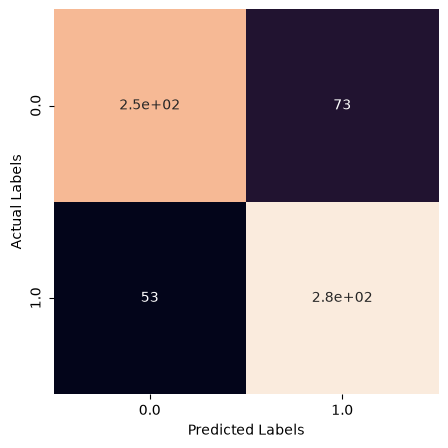

In [12]:
from sklearn.model_selection import train_test_split, cross_val_predict, cross_validate, GridSearchCV
from sklearn.metrics import confusion_matrix, classification_report
from sklearn.linear_model import LogisticRegression 

# Reserve 30% of observations for held-out evaluation.
X_ad_e_s_train, X_ad_e_s_test, y_ad_e_s_train, y_ad_e_s_test = train_test_split(X_ad_e_s, y_ad_e_s,
                                                                                test_size=0.3,
                                                                                stratify=y_ad_e_s,
                                                                                random_state=43)
# Stratification keeps the relative frequencies of the income groups similar across partitions.

# Construct the logistic-regression baseline.
logistic_regression_m_ad = LogisticRegression()

ads.custom_crossvalidation(X_ad_e_s_train, y_ad_e_s_train, logistic_regression_m_ad, cv_=5)

### Selecting logistic-regression settings

The notebook evaluates multiple values for the inverse regularization strength (`C`), penalty (`l1`, `l2`, `elasticnet`), solver, iteration limit, stopping tolerance, intercept use and class weighting.

The supplied `ads.custom_crossvalidation_gridsearch` helper explores these combinations with five-fold cross-validation. The grid includes some incompatible solver/penalty combinations; the behaviour of those combinations is determined by the existing helper and scikit-learn settings. The parameter grid and helper call have not been changed.

Best parameters found: {'C': 0.1, 'class_weight': None, 'fit_intercept': True, 'max_iter': 100, 'penalty': 'l2', 'solver': 'lbfgs', 'tol': 0.01}
Mean accuracy: 82.62% +/-3.94%
Mean precision: 83.06% +/-4.04%
Mean recall: 82.56% +/-3.94%
Mean F1-score is 82.55% +/-3.94%
              precision    recall  f1-score   support

         0.0       0.86      0.78      0.81       326
         1.0       0.80      0.88      0.84       336

    accuracy                           0.83       662
   macro avg       0.83      0.83      0.83       662
weighted avg       0.83      0.83      0.83       662



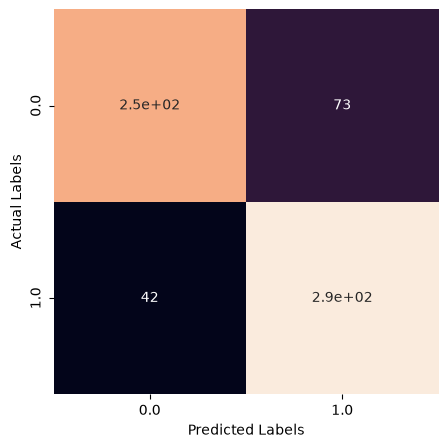

In [13]:
# Enumerate candidate configurations for model selection.
logistic_regression_param_grid = {
    'C': [0.01, 0.1, 1, 10, 100],  # Inverse regularization magnitude
    'penalty': ['l1', 'l2', 'elasticnet'],  # Candidate penalty formulations
    'solver': ['liblinear', 'saga', 'newton-cg', 'lbfgs'],  # Available optimization backends
    'max_iter': [100, 200],  # Iteration caps for convergence
    'tol': [1e-4, 1e-3, 1e-2],  # Solver termination tolerances
    'fit_intercept': [True, False],  # Include or omit the bias term
    'class_weight': [None, 'balanced']  # Default versus class-balanced weighting
}

# Evaluate configurations using the supplied cross-validation utility.
best_logistic_regression_m_ad, best_logistic_regression_m_ad_params, best_logistic_regression_m_ad_preds = (
    ads.custom_crossvalidation_gridsearch(
        X_ad_e_s_train, 
        y_ad_e_s_train, 
        logistic_regression_m_ad, 
        logistic_regression_param_grid, 
        cv_=5
    )
)

### Reading the logistic-regression evaluation

The next cells report class-specific classification metrics for the held-out observations. They have complementary interpretations:

| Measure | Interpretation |
| --- | --- |
| Accuracy | Proportion of all observations assigned the correct class |
| Precision | Among predictions of a given class, how many are correct |
| Recall | Among observations truly belonging to a class, how many are found |
| F1 score | Harmonic mean of precision and recall |
| Support | Number of true examples belonging to each class |

For binary predictions, the usual definitions are:

$$
\mathrm{Accuracy}=\frac{TP+TN}{TP+TN+FP+FN},\qquad
\mathrm{Precision}=\frac{TP}{TP+FP},
$$

$$
\mathrm{Recall}=\frac{TP}{TP+FN},\qquad
F_1=\frac{2\,\mathrm{Precision}\,\mathrm{Recall}}{\mathrm{Precision}+\mathrm{Recall}}.
$$

Read the printed report alongside the confusion matrix rather than relying only on a single aggregate score. Differences between the `<=50K` and `>50K` classes are important when the income groups are not equally represented.

**Interpretation convention:** the numerical values in the code-cell outputs are the reference for this run. The definitions above do not assume a particular achieved score.

              precision    recall  f1-score   support

         0.0       0.85      0.70      0.77       141
         1.0       0.75      0.88      0.81       144

    accuracy                           0.79       285
   macro avg       0.80      0.79      0.79       285
weighted avg       0.80      0.79      0.79       285



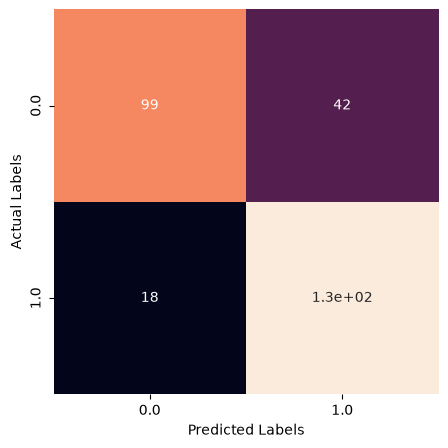

In [14]:
# Use the previously prepared test predictors.
# Generate predictions with the selected estimator.
y_ad_e_s_test_predicted = best_logistic_regression_m_ad.predict(X_ad_e_s_test)
print(classification_report(y_ad_e_s_test, y_ad_e_s_test_predicted))
ads.plot_confusion_matrix(y_ad_e_s_test, y_ad_e_s_test_predicted)

### Examining predicted probabilities

For estimators that implement `predict_proba`, the output consists of estimated class probabilities for each observation. These probabilities can help distinguish confident from borderline predictions, although calibration should not be assumed without an additional check.

The existing utility `ads.get_test_dataset` is used to inspect predictions after fitting. Some other classifier families require extra configuration to expose probabilities; that distinction does not alter the steps below.

In [15]:
# Refit the selected estimator on the training partition.
best_logistic_regression_m_ad.fit(X_ad_e_s_train, y_ad_e_s_train)
# Use the existing helper to inspect fitted-model predictions.
ads.get_test_dataset(best_logistic_regression_m_ad, X_ad_e_s_train, y_ad_e_s_train)

,age,capital_gain,capital_loss,education_10th,education_11th,education_12th,education_1st-4th,education_5th-6th,education_7th-8th,education_9th,...,workclass_Federal-gov,workclass_Local-gov,workclass_Private,workclass_Self-emp-inc,workclass_Self-emp-not-inc,workclass_State-gov,true labels,predictions,confidence_0.0,confidence_1.0
769,-1.280600,-0.194897,-0.271324,1.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.922952,0.077048
120,1.441394,0.561235,-0.271324,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,1.0,0.0,0.0,0.0,1.0,1.0,0.125354,0.874646
399,-0.480014,0.561235,-0.271324,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,1.0,0.0,0.0,0.0,1.0,1.0,0.230178,0.769822
315,-0.319896,-0.194897,-0.271324,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,1.0,0.0,0.0,0.0,1.0,1.0,0.371869,0.628131
297,-0.480014,-0.194897,-0.271324,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,1.0,0.0,0.0,0.0,1.0,1.0,0.241098,0.758902
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
528,-1.360659,-0.194897,-0.271324,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.979650,0.020350
182,-0.560072,-0.194897,-0.271324,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,1.0,0.0,0.0,0.0,1.0,1.0,0.442259,0.557741
35,-0.800248,-0.194897,-0.271324,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,1.0,0.0,0.0,1.0,1.0,0.188831,0.811169
323,0.240514,-0.194897,-0.271324,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.603527,0.396473


## Rule-based models: decision trees

A classification tree recursively divides observations according to feature tests. The resulting paths describe a sequence of decision rules, while terminal leaves supply class predictions. The split criterion may use Gini impurity, entropy or log loss.

A tree with too much freedom can memorize its training examples. Accordingly, this notebook first fits a baseline `sklearn.tree.DecisionTreeClassifier`, then examines constrained trees and cost-complexity pruning. The code uses **scikit-learn decision trees**, not a separate C5.0 implementation.

This part of the workflow also uses an ordinal encoding of the categorical predictors, as written in the original notebook. Its numerical category codes should be interpreted as implementation inputs, not as natural rankings.

In [16]:
ad = adult_data.copy()
ad

,age,workclass,fnlwgt,education,education_num,marital_status,occupation,relationship,race,sex,capital_gain,capital_loss,hours_per_week,native_country,label
0,49.0,Self-emp-inc,191681.0,Some-college,10.0,Married-civ-spouse,Exec-managerial,Husband,White,Male,0.0,0.0,50.0,United-States,>50K
1,56.0,Self-emp-not-inc,335605.0,HS-grad,9.0,Married-civ-spouse,Other-service,Husband,White,Male,0.0,1887.0,50.0,Canada,>50K
2,40.0,Private,207578.0,Assoc-acdm,12.0,Married-civ-spouse,Tech-support,Husband,White,Male,0.0,1977.0,60.0,United-States,>50K
3,24.0,Private,279472.0,Some-college,10.0,Married-civ-spouse,Machine-op-inspct,Wife,White,Female,7298.0,0.0,48.0,United-States,>50K
4,34.0,Private,142897.0,Masters,14.0,Married-civ-spouse,Exec-managerial,Husband,Asian-Pac-Islander,Male,7298.0,0.0,35.0,Taiwan,>50K
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
942,30.0,Private,33678.0,HS-grad,9.0,Never-married,Sales,Own-child,White,Male,0.0,0.0,40.0,United-States,<=50K
943,31.0,Private,47151.0,HS-grad,9.0,Never-married,Other-service,Not-in-family,White,Female,0.0,0.0,56.0,United-States,<=50K
944,61.0,Self-emp-not-inc,50483.0,7th-8th,4.0,Married-civ-spouse,Farming-fishing,Husband,White,Male,0.0,0.0,56.0,United-States,<=50K
945,50.0,Private,485710.0,Doctorate,16.0,Divorced,Prof-specialty,Not-in-family,White,Female,0.0,0.0,50.0,United-States,<=50K


In [17]:
X_ad = ad[ad.columns.difference(['label'])]
X_ad

,age,capital_gain,capital_loss,education,education_num,fnlwgt,hours_per_week,marital_status,native_country,occupation,race,relationship,sex,workclass
0,49.0,0.0,0.0,Some-college,10.0,191681.0,50.0,Married-civ-spouse,United-States,Exec-managerial,White,Husband,Male,Self-emp-inc
1,56.0,0.0,1887.0,HS-grad,9.0,335605.0,50.0,Married-civ-spouse,Canada,Other-service,White,Husband,Male,Self-emp-not-inc
2,40.0,0.0,1977.0,Assoc-acdm,12.0,207578.0,60.0,Married-civ-spouse,United-States,Tech-support,White,Husband,Male,Private
3,24.0,7298.0,0.0,Some-college,10.0,279472.0,48.0,Married-civ-spouse,United-States,Machine-op-inspct,White,Wife,Female,Private
4,34.0,7298.0,0.0,Masters,14.0,142897.0,35.0,Married-civ-spouse,Taiwan,Exec-managerial,Asian-Pac-Islander,Husband,Male,Private
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
942,30.0,0.0,0.0,HS-grad,9.0,33678.0,40.0,Never-married,United-States,Sales,White,Own-child,Male,Private
943,31.0,0.0,0.0,HS-grad,9.0,47151.0,56.0,Never-married,United-States,Other-service,White,Not-in-family,Female,Private
944,61.0,0.0,0.0,7th-8th,4.0,50483.0,56.0,Married-civ-spouse,United-States,Farming-fishing,White,Husband,Male,Self-emp-not-inc
945,50.0,0.0,0.0,Doctorate,16.0,485710.0,50.0,Divorced,United-States,Prof-specialty,White,Not-in-family,Female,Private


In [18]:
y_ad = ad[['label']] 
y_ad

,label
0,>50K
1,>50K
2,>50K
3,>50K
4,>50K
...,...
942,<=50K
943,<=50K
944,<=50K
945,<=50K


In [19]:
from sklearn.preprocessing import OrdinalEncoder

# Prepare integer category codes for tree inputs.
encoder = OrdinalEncoder()

# Locate features stored as strings.
X_ad_c = X_ad.select_dtypes(include=['object']).columns

# Convert categories to codes for this tree workflow.
X_ad_c_e = encoder.fit_transform(X_ad[X_ad_c])

# Restore feature labels in a pandas table.
X_ad_c_e = pd.DataFrame(X_ad_c_e, columns=encoder.get_feature_names_out(X_ad_c))

# Assemble continuous predictors alongside the encoded categories.
X_ad_e = pd.concat([X_ad.drop(columns=X_ad_c), X_ad_c_e], axis=1)

# Inspect the resulting feature table.
X_ad_e.info()

<class 'pandas.DataFrame'>
RangeIndex: 947 entries, 0 to 946
Data columns (total 14 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             947 non-null    float64
 1   capital_gain    947 non-null    float64
 2   capital_loss    947 non-null    float64
 3   education_num   947 non-null    float64
 4   fnlwgt          947 non-null    float64
 5   hours_per_week  947 non-null    float64
 6   education       947 non-null    float64
 7   marital_status  947 non-null    float64
 8   native_country  947 non-null    float64
 9   occupation      947 non-null    float64
 10  race            947 non-null    float64
 11  relationship    947 non-null    float64
 12  sex             947 non-null    float64
 13  workclass       947 non-null    float64
dtypes: float64(14)
memory usage: 103.7 KB


Mean accuracy: 76.44% +/-3.86%
Mean precision: 76.49% +/-3.83%
Mean recall: 76.45% +/-3.86%
Mean F1-score is 76.43% +/-3.87%
              precision    recall  f1-score   support

       <=50K       0.76      0.76      0.76       326
        >50K       0.77      0.77      0.77       336

    accuracy                           0.76       662
   macro avg       0.76      0.76      0.76       662
weighted avg       0.76      0.76      0.76       662



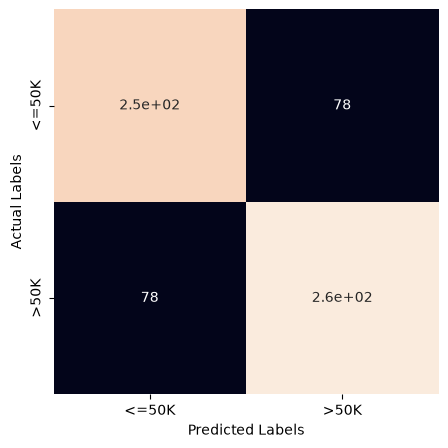

In [20]:
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_graphviz

# Reserve 30% of observations for held-out evaluation.
X_ad_e_train, X_ad_e_test, y_ad_train, y_ad_test = train_test_split(X_ad_e, y_ad,
                                                                    test_size=0.3,
                                                                    stratify=y_ad,
                                                                    random_state=43)
# Stratification keeps the relative frequencies of the income groups similar across partitions.

# Set up the baseline classification tree.
decision_tree_classifier_m_ad = DecisionTreeClassifier(random_state=43)

ads.custom_crossvalidation(X_ad_e_train, y_ad_train, decision_tree_classifier_m_ad)

[Text(0.6002168525402726, 0.9807692307692307, 'relationship <= 0.5\ngini = 0.5\nsamples = 662\nvalue = [326, 336]\nclass = >50K'),
 Text(0.34045848822800495, 0.9423076923076923, 'education_num <= 12.5\ngini = 0.363\nsamples = 348\nvalue = [83, 265]\nclass = >50K'),
 Text(0.47033767038413876, 0.9615384615384615, 'True  '),
 Text(0.24349442379182157, 0.9038461538461539, 'capital_gain <= 4782.0\ngini = 0.446\nsamples = 217\nvalue = [73, 144]\nclass = >50K'),
 Text(0.23358116480793062, 0.8653846153846154, 'education_num <= 8.5\ngini = 0.47\nsamples = 193\nvalue = [73, 120]\nclass = >50K'),
 Text(0.19888475836431227, 0.8269230769230769, 'fnlwgt <= 130518.5\ngini = 0.453\nsamples = 26\nvalue = [17, 9]\nclass = <=50K'),
 Text(0.18897149938042132, 0.7884615384615384, 'gini = 0.0\nsamples = 7\nvalue = [7, 0]\nclass = <=50K'),
 Text(0.20879801734820322, 0.7884615384615384, 'age <= 43.0\ngini = 0.499\nsamples = 19\nvalue = [10, 9]\nclass = <=50K'),
 Text(0.18897149938042132, 0.75, 'age <= 34.0\ng

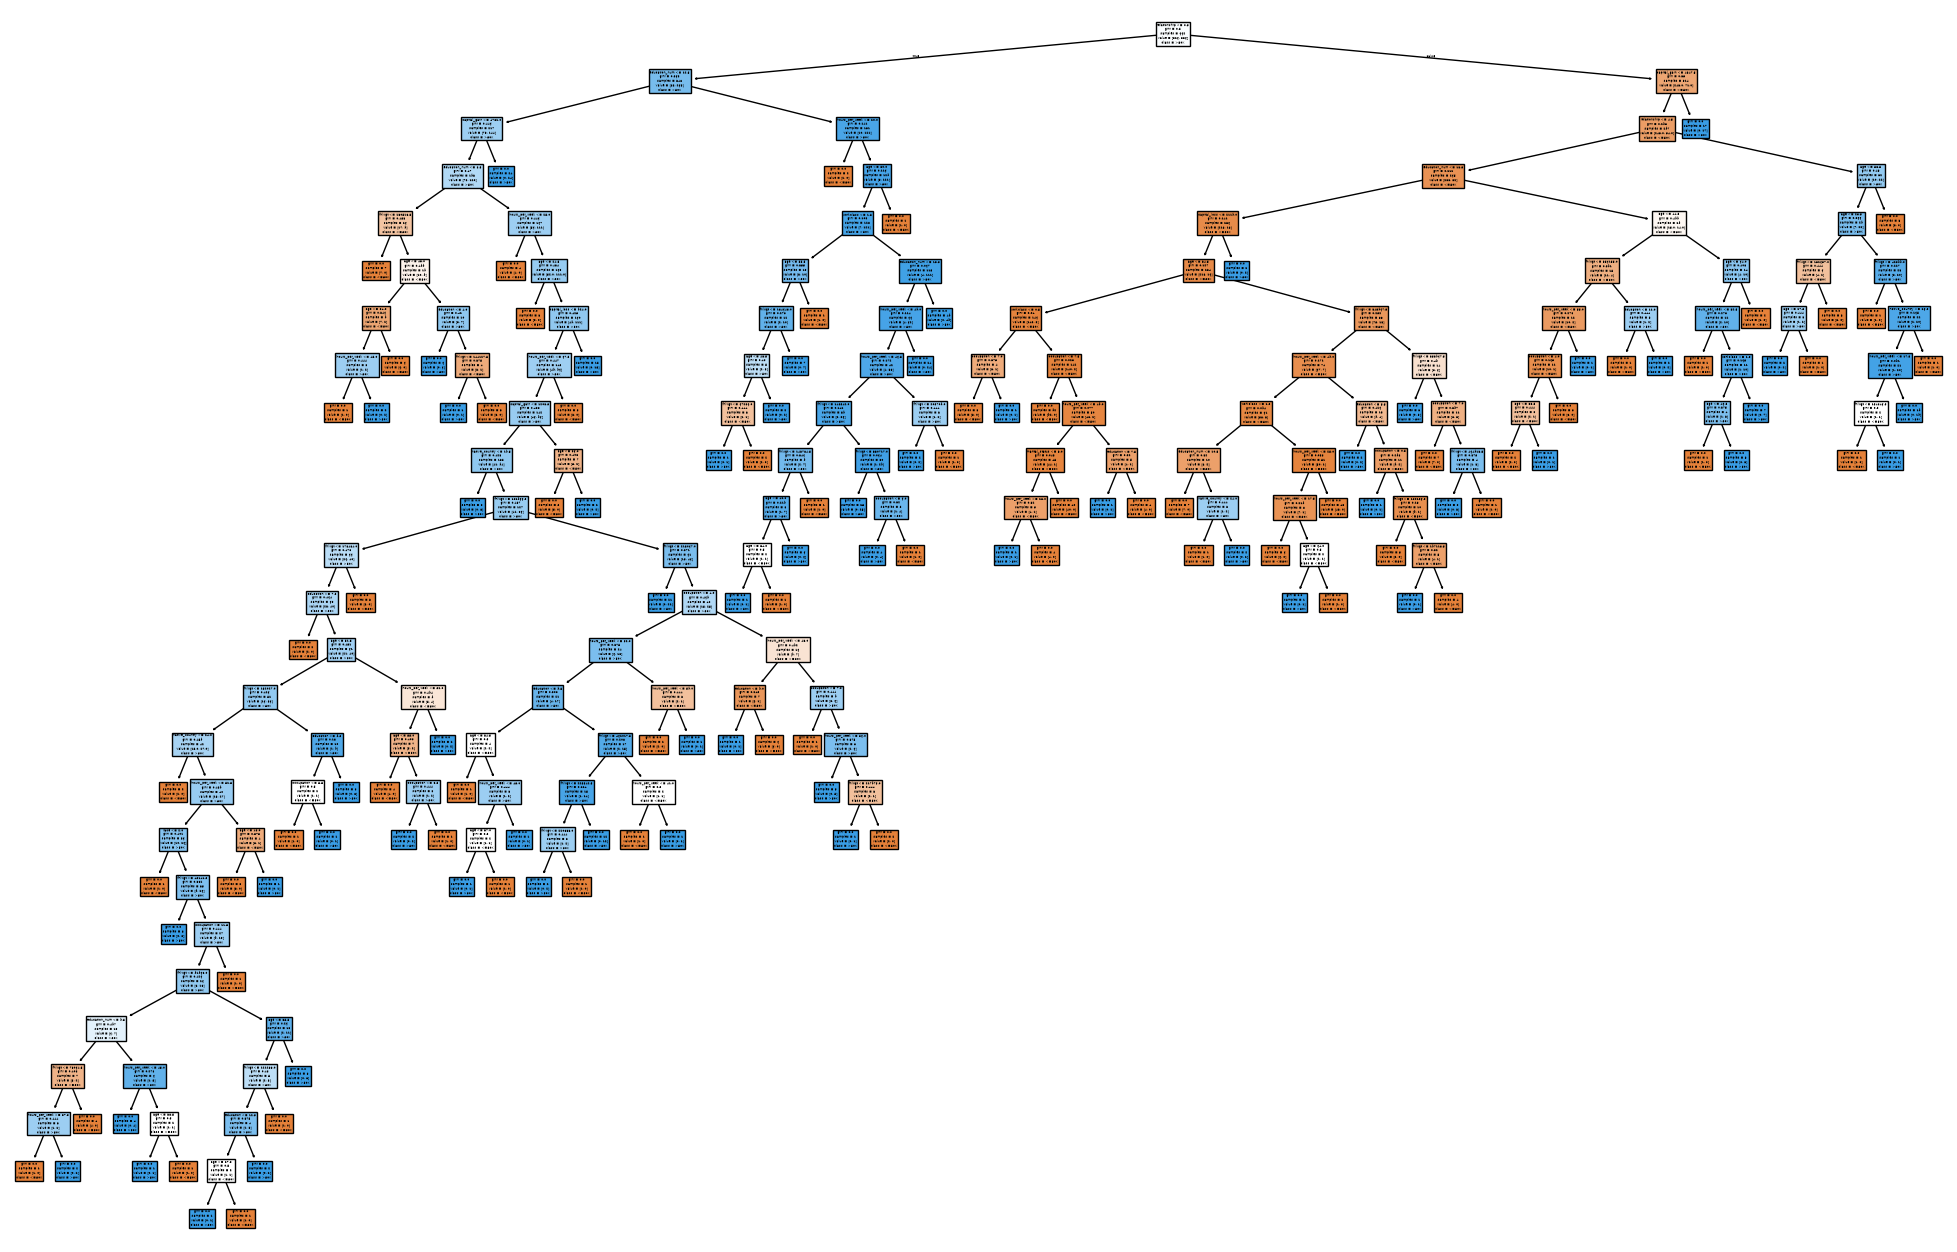

In [21]:
# Fit the baseline tree and visualize its learned splits.
decision_tree_classifier_m_ad.fit(X_ad_e_train, y_ad_train)
plt.figure(figsize=(25, 16))
plot_tree(decision_tree_classifier_m_ad, 
          filled=True, 
          feature_names=list(X_ad_e_train.columns), 
          class_names=decision_tree_classifier_m_ad.classes_)

In [22]:
# Inspect the fitted tree size through depth and leaf count.
decision_tree_classifier_m_ad.get_depth(), decision_tree_classifier_m_ad.get_n_leaves()

(25, np.int64(123))

In [23]:
print(decision_tree_classifier_m_ad.classes_)

['<=50K' '>50K']


In [24]:
decision_tree_classifier_m_ad.decision_path(X_ad_e_train, check_input=True)

<Compressed Sparse Row sparse matrix of dtype 'int64'
	with 7075 stored elements and shape (662, 245)>

### Managing tree complexity

Two complementary controls are explored:

- **Pre-pruning:** limit depth or require minimum sample counts for splits and leaves (`max_depth`, `min_samples_split`, `min_samples_leaf`).
- **Post-pruning:** use `ccp_alpha` to remove branches under a cost-complexity criterion.

The cells compare these approaches separately and in combination, using the existing parameter values.

Mean accuracy: 80.66% +/-3.81%
Mean precision: 81.06% +/-3.86%
Mean recall: 80.58% +/-3.79%
Mean F1-score is 80.57% +/-3.82%
              precision    recall  f1-score   support

       <=50K       0.84      0.75      0.79       326
        >50K       0.78      0.86      0.82       336

    accuracy                           0.81       662
   macro avg       0.81      0.81      0.81       662
weighted avg       0.81      0.81      0.81       662



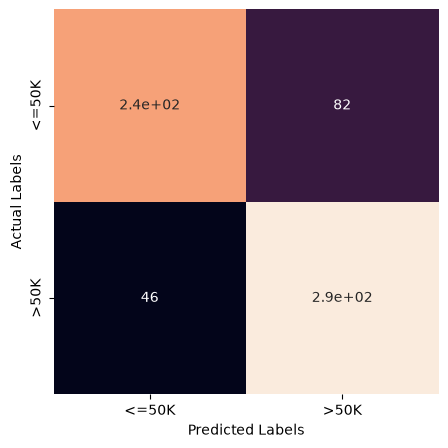

In [25]:
# Constrain tree growth at construction time.
decision_tree_classifier_m_ad_pre = DecisionTreeClassifier(max_depth=8, min_samples_split=2, min_samples_leaf=1, random_state=43)
ads.custom_crossvalidation(X_ad_e_train, y_ad_train, decision_tree_classifier_m_ad_pre)

8 50


[Text(0.5174180327868853, 0.9444444444444444, 'relationship <= 0.5\ngini = 0.5\nsamples = 662\nvalue = [326, 336]\nclass = >50K'),
 Text(0.2336065573770492, 0.8333333333333334, 'education_num <= 12.5\ngini = 0.363\nsamples = 348\nvalue = [83, 265]\nclass = >50K'),
 Text(0.3755122950819672, 0.8888888888888888, 'True  '),
 Text(0.13934426229508196, 0.7222222222222222, 'capital_gain <= 4782.0\ngini = 0.446\nsamples = 217\nvalue = [73, 144]\nclass = >50K'),
 Text(0.12295081967213115, 0.6111111111111112, 'education_num <= 8.5\ngini = 0.47\nsamples = 193\nvalue = [73, 120]\nclass = >50K'),
 Text(0.06557377049180328, 0.5, 'fnlwgt <= 130518.5\ngini = 0.453\nsamples = 26\nvalue = [17, 9]\nclass = <=50K'),
 Text(0.04918032786885246, 0.3888888888888889, 'gini = 0.0\nsamples = 7\nvalue = [7, 0]\nclass = <=50K'),
 Text(0.08196721311475409, 0.3888888888888889, 'age <= 43.0\ngini = 0.499\nsamples = 19\nvalue = [10, 9]\nclass = <=50K'),
 Text(0.04918032786885246, 0.2777777777777778, 'age <= 34.0\ngini

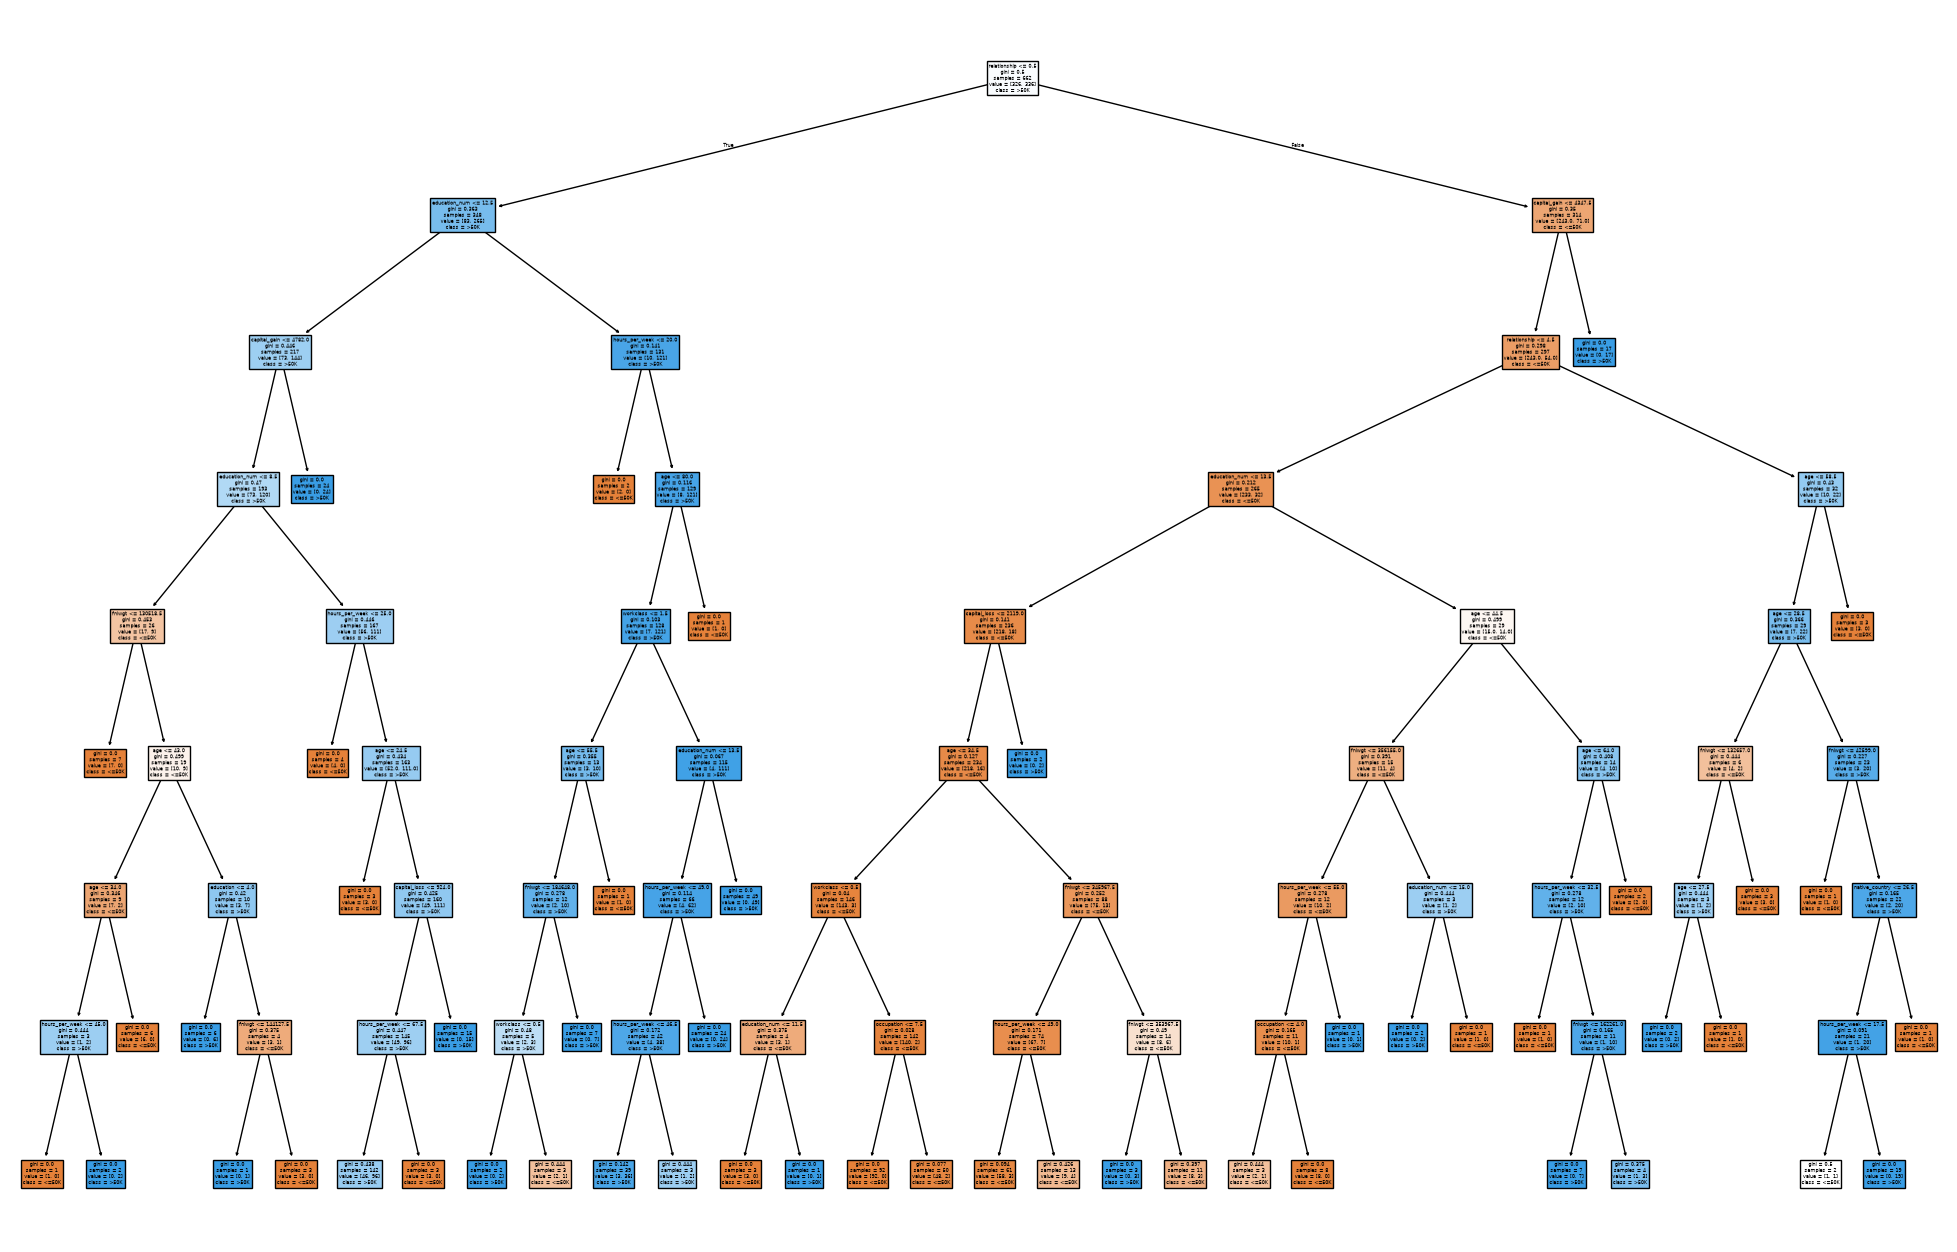

In [26]:
decision_tree_classifier_m_ad_pre.fit(X_ad_e_train, y_ad_train)
print(decision_tree_classifier_m_ad_pre.get_depth(), decision_tree_classifier_m_ad_pre.get_n_leaves())
plt.figure(figsize=(25, 16))
plot_tree(decision_tree_classifier_m_ad_pre, 
          filled=True, 
          feature_names=list(X_ad_e_train.columns), 
          class_names=decision_tree_classifier_m_ad_pre.classes_)

In [27]:
# Inspect the fitted tree size through depth and leaf count.
decision_tree_classifier_m_ad_pre.get_depth(), decision_tree_classifier_m_ad_pre.get_n_leaves()

(8, np.int64(50))

In [28]:
print(decision_tree_classifier_m_ad_pre.classes_)

['<=50K' '>50K']


In [29]:
decision_tree_classifier_m_ad_pre.decision_path(X_ad_e_train, check_input=True)

<Compressed Sparse Row sparse matrix of dtype 'int64'
	with 5486 stored elements and shape (662, 99)>

Mean accuracy: 80.66% +/-2.85%
Mean precision: 81.30% +/-2.95%
Mean recall: 80.57% +/-2.83%
Mean F1-score is 80.53% +/-2.85%
              precision    recall  f1-score   support

       <=50K       0.85      0.74      0.79       326
        >50K       0.78      0.87      0.82       336

    accuracy                           0.81       662
   macro avg       0.81      0.81      0.81       662
weighted avg       0.81      0.81      0.81       662



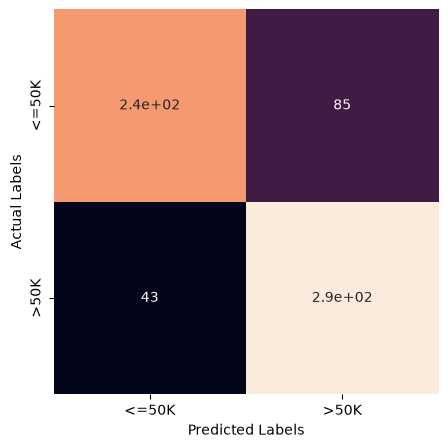

In [30]:
# Apply cost-complexity pruning after tree construction.
decision_tree_classifier_m_ad_post = DecisionTreeClassifier(ccp_alpha=0.005, random_state=43)
ads.custom_crossvalidation(X_ad_e_train, y_ad_train, decision_tree_classifier_m_ad_post)

5 11


[Text(0.6071428571428571, 0.9166666666666666, 'relationship <= 0.5\ngini = 0.5\nsamples = 662\nvalue = [326, 336]\nclass = >50K'),
 Text(0.35714285714285715, 0.75, 'education_num <= 12.5\ngini = 0.363\nsamples = 348\nvalue = [83, 265]\nclass = >50K'),
 Text(0.4821428571428571, 0.8333333333333333, 'True  '),
 Text(0.21428571428571427, 0.5833333333333334, 'capital_gain <= 4782.0\ngini = 0.446\nsamples = 217\nvalue = [73, 144]\nclass = >50K'),
 Text(0.14285714285714285, 0.4166666666666667, 'education_num <= 8.5\ngini = 0.47\nsamples = 193\nvalue = [73, 120]\nclass = >50K'),
 Text(0.07142857142857142, 0.25, 'gini = 0.453\nsamples = 26\nvalue = [17, 9]\nclass = <=50K'),
 Text(0.21428571428571427, 0.25, 'hours_per_week <= 25.0\ngini = 0.446\nsamples = 167\nvalue = [56, 111]\nclass = >50K'),
 Text(0.14285714285714285, 0.08333333333333333, 'gini = 0.0\nsamples = 4\nvalue = [4, 0]\nclass = <=50K'),
 Text(0.2857142857142857, 0.08333333333333333, 'gini = 0.434\nsamples = 163\nvalue = [52.0, 111.0

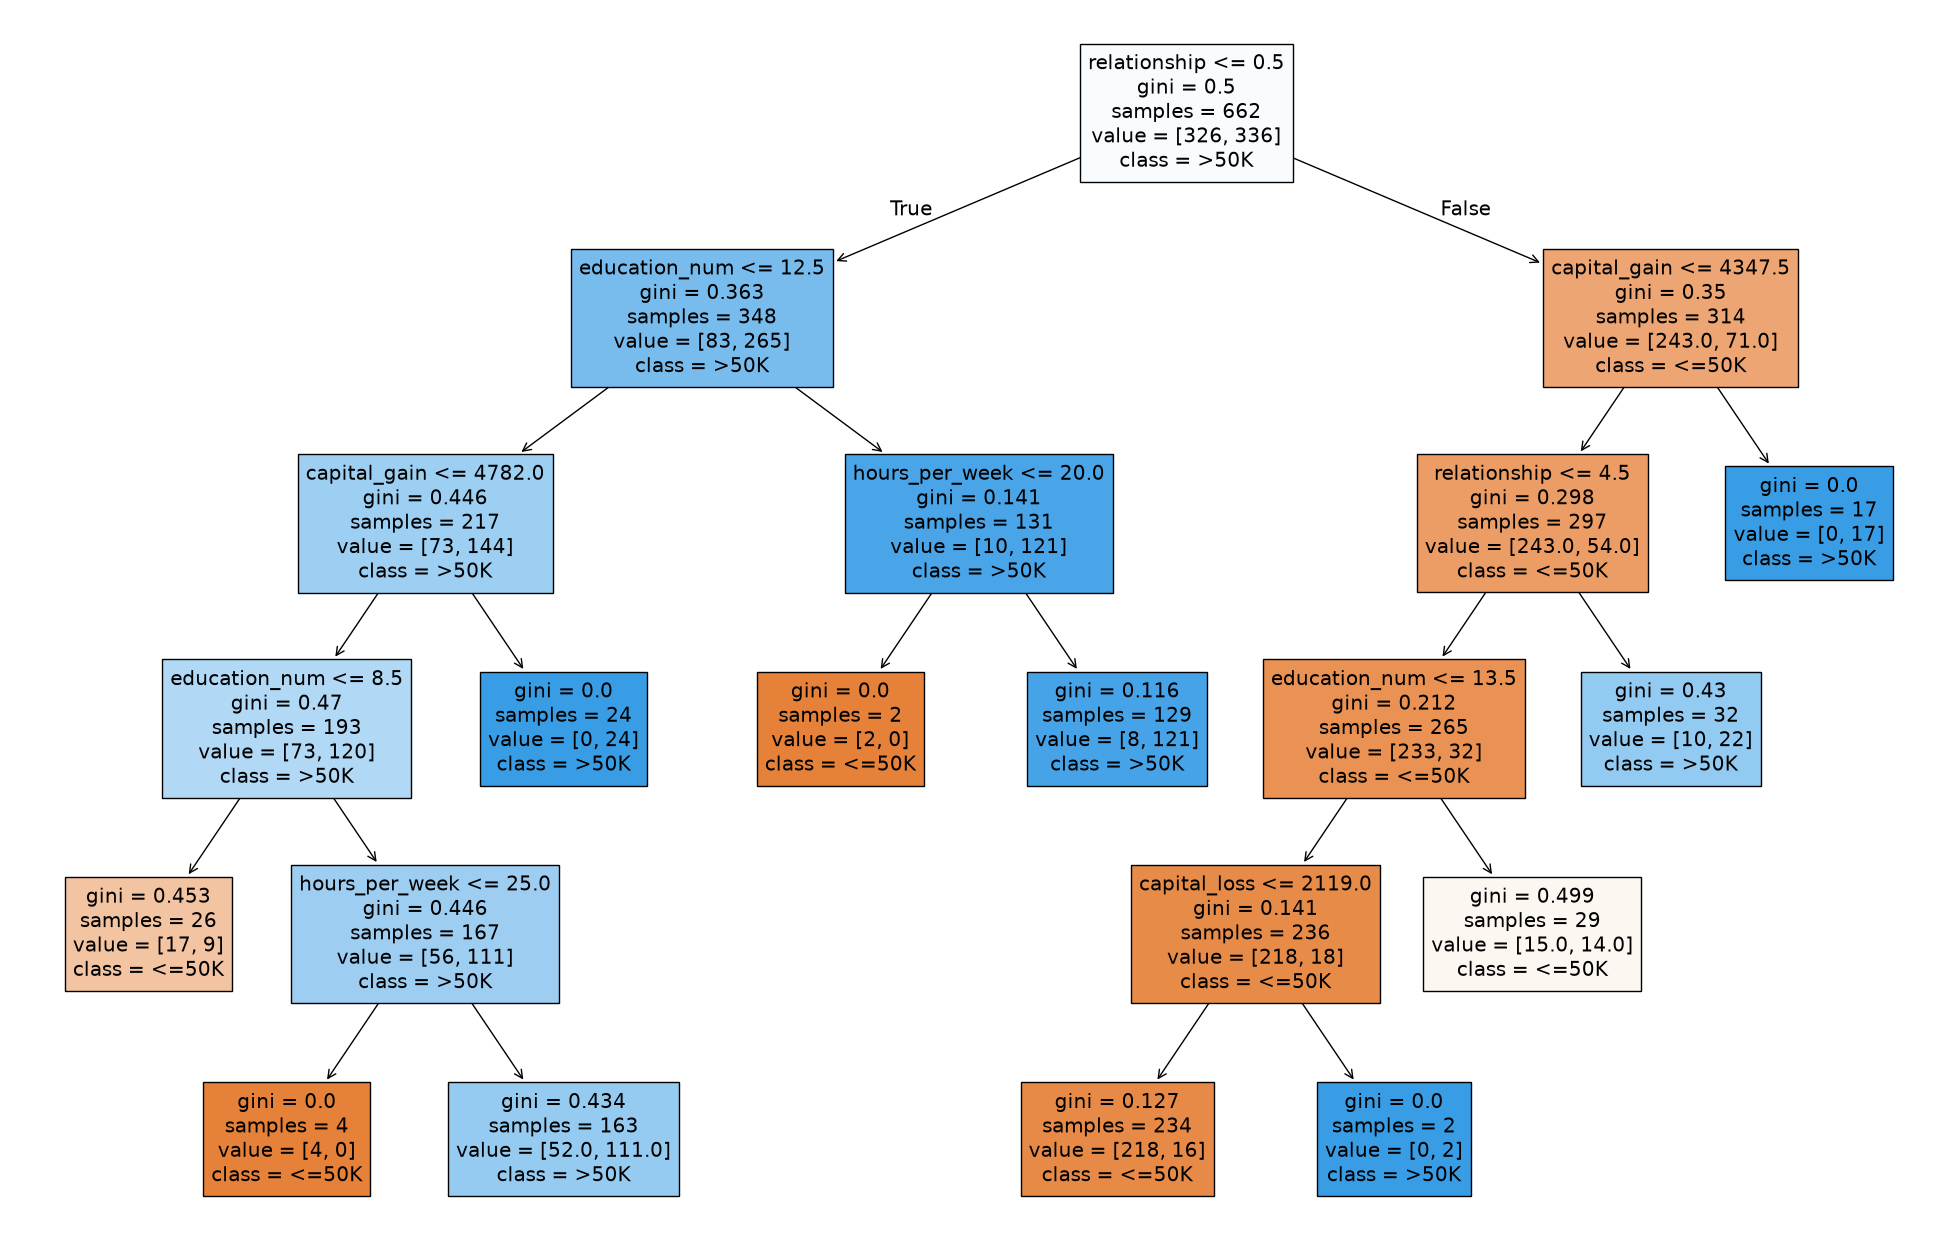

In [31]:
decision_tree_classifier_m_ad_post.fit(X_ad_e_train, y_ad_train)
print(decision_tree_classifier_m_ad_post.get_depth(), decision_tree_classifier_m_ad_post.get_n_leaves())
plt.figure(figsize=(25, 16))
plot_tree(decision_tree_classifier_m_ad_post, 
          filled=True, 
          feature_names=list(X_ad_e_train.columns), 
          class_names=decision_tree_classifier_m_ad_post.classes_)

In [32]:
# Inspect the fitted tree size through depth and leaf count.
decision_tree_classifier_m_ad_post.get_depth(), decision_tree_classifier_m_ad_post.get_n_leaves()

(5, np.int64(11))

In [33]:
print(decision_tree_classifier_m_ad_post.classes_)

['<=50K' '>50K']


In [34]:
decision_tree_classifier_m_ad_post.decision_path(X_ad_e_train, check_input=True)

<Compressed Sparse Row sparse matrix of dtype 'int64'
	with 3492 stored elements and shape (662, 21)>

Mean accuracy: 80.36% +/-3.31%
Mean precision: 80.98% +/-3.48%
Mean recall: 80.27% +/-3.29%
Mean F1-score is 80.23% +/-3.30%
              precision    recall  f1-score   support

       <=50K       0.84      0.74      0.79       326
        >50K       0.77      0.87      0.82       336

    accuracy                           0.80       662
   macro avg       0.81      0.80      0.80       662
weighted avg       0.81      0.80      0.80       662



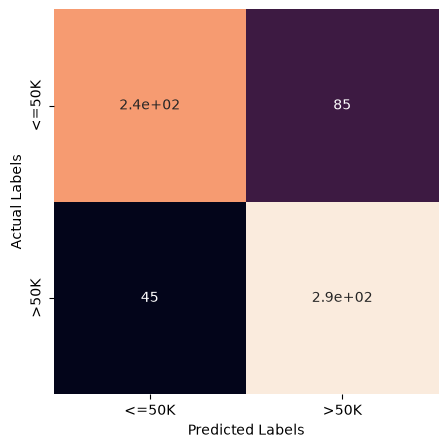

In [35]:
# Combine growth limits with cost-complexity pruning.
decision_tree_classifier_m_ad_prepost = DecisionTreeClassifier(max_depth=8, min_samples_split=2,min_samples_leaf=1, ccp_alpha=0.005,random_state=43)
ads.custom_crossvalidation(X_ad_e_train, y_ad_train, decision_tree_classifier_m_ad_prepost)

5 11


[Text(0.6071428571428571, 0.9166666666666666, 'relationship <= 0.5\ngini = 0.5\nsamples = 662\nvalue = [326, 336]\nclass = >50K'),
 Text(0.35714285714285715, 0.75, 'education_num <= 12.5\ngini = 0.363\nsamples = 348\nvalue = [83, 265]\nclass = >50K'),
 Text(0.4821428571428571, 0.8333333333333333, 'True  '),
 Text(0.21428571428571427, 0.5833333333333334, 'capital_gain <= 4782.0\ngini = 0.446\nsamples = 217\nvalue = [73, 144]\nclass = >50K'),
 Text(0.14285714285714285, 0.4166666666666667, 'education_num <= 8.5\ngini = 0.47\nsamples = 193\nvalue = [73, 120]\nclass = >50K'),
 Text(0.07142857142857142, 0.25, 'gini = 0.453\nsamples = 26\nvalue = [17, 9]\nclass = <=50K'),
 Text(0.21428571428571427, 0.25, 'hours_per_week <= 25.0\ngini = 0.446\nsamples = 167\nvalue = [56, 111]\nclass = >50K'),
 Text(0.14285714285714285, 0.08333333333333333, 'gini = 0.0\nsamples = 4\nvalue = [4, 0]\nclass = <=50K'),
 Text(0.2857142857142857, 0.08333333333333333, 'gini = 0.434\nsamples = 163\nvalue = [52.0, 111.0

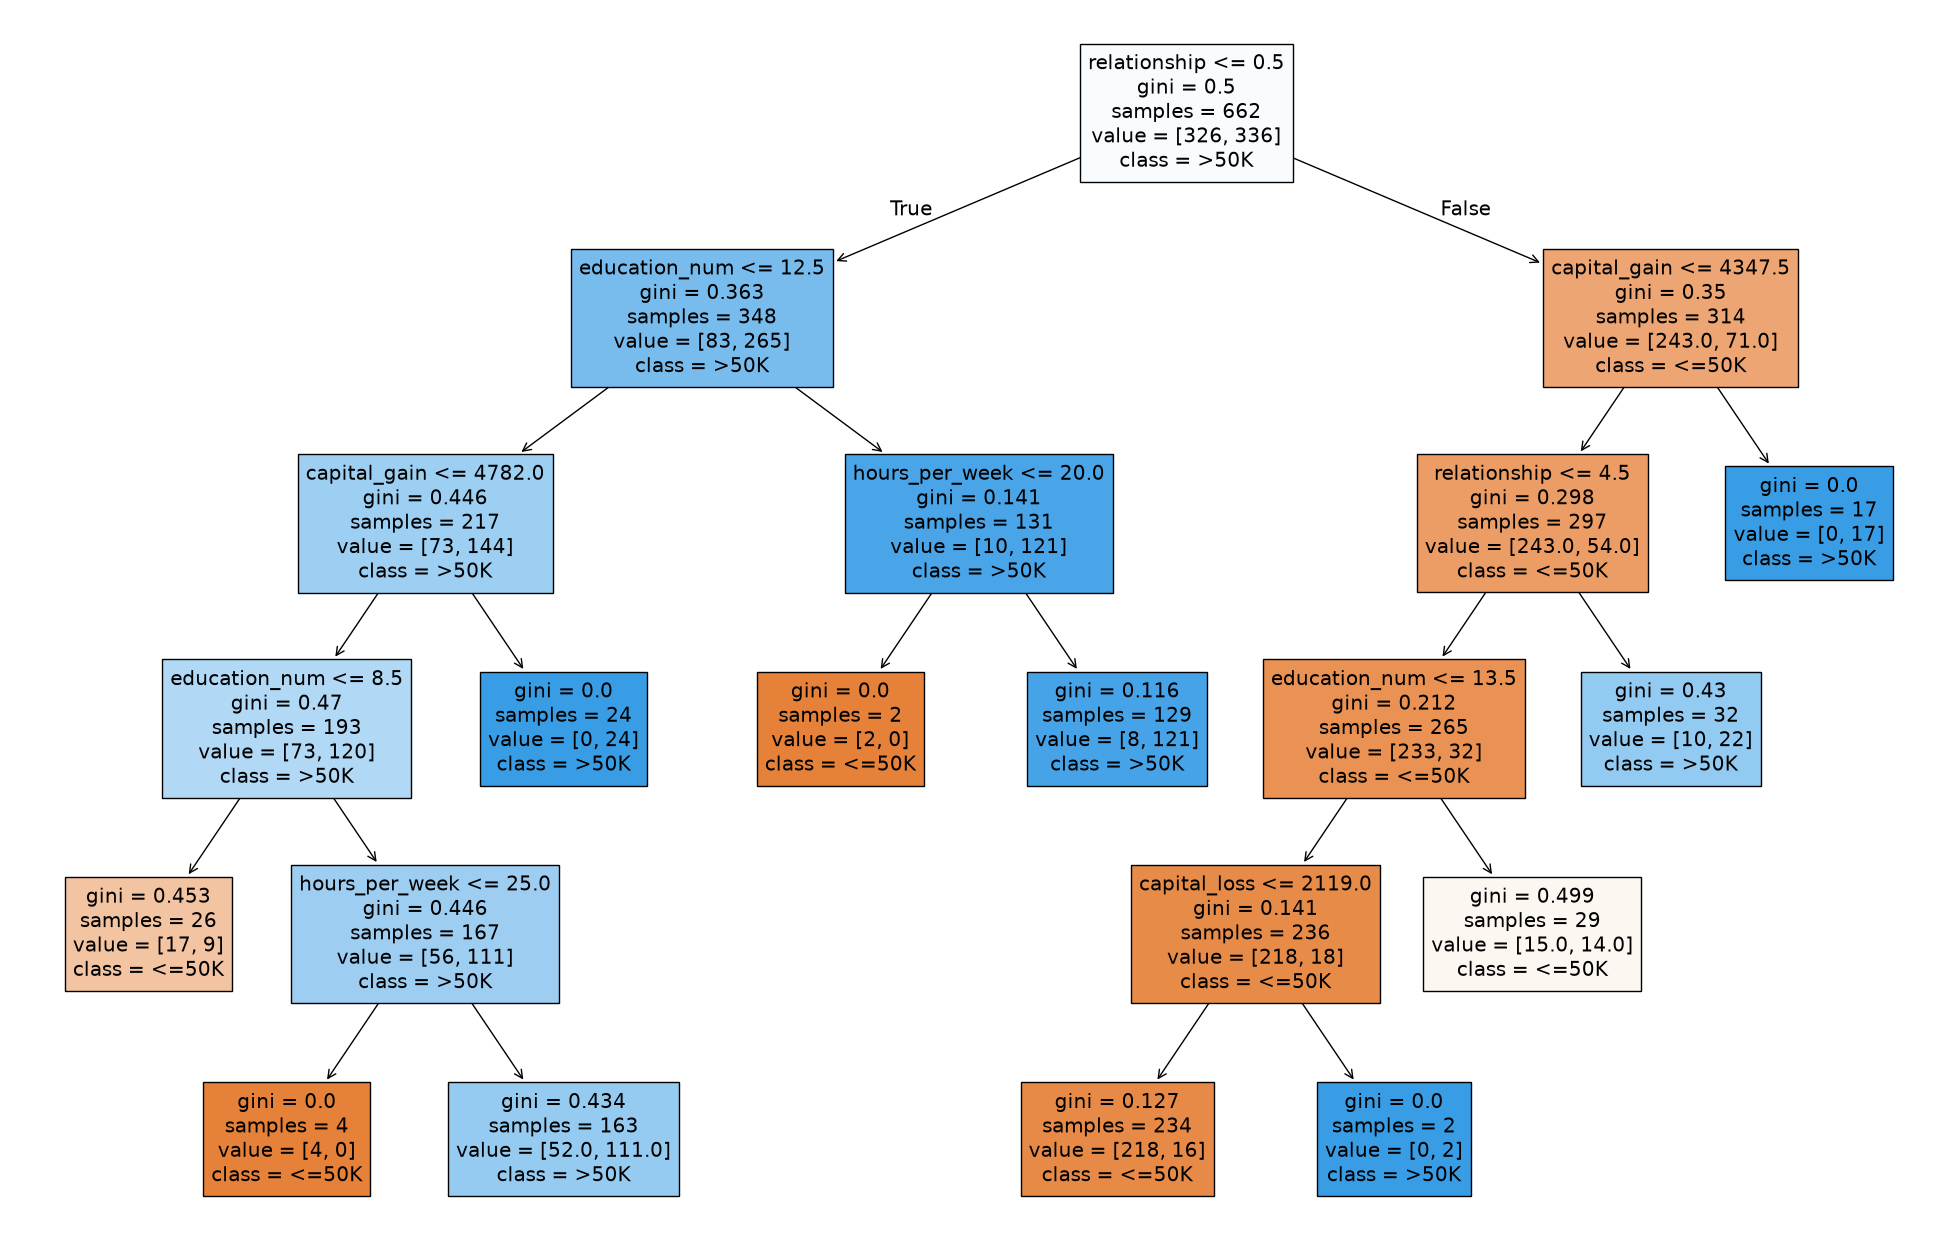

In [36]:
decision_tree_classifier_m_ad_prepost.fit(X_ad_e_train, y_ad_train)
print(decision_tree_classifier_m_ad_prepost.get_depth(), decision_tree_classifier_m_ad_prepost.get_n_leaves())
plt.figure(figsize=(25, 16))
plot_tree(decision_tree_classifier_m_ad_prepost, 
          filled=True, 
          feature_names=list(X_ad_e_train.columns), 
          class_names=decision_tree_classifier_m_ad_prepost.classes_)

In [37]:
# Inspect the fitted tree size through depth and leaf count.
decision_tree_classifier_m_ad_prepost.get_depth(), decision_tree_classifier_m_ad_prepost.get_n_leaves()

(5, np.int64(11))

In [38]:
print(decision_tree_classifier_m_ad_prepost.classes_)

['<=50K' '>50K']


In [39]:
decision_tree_classifier_m_ad_prepost.decision_path(X_ad_e_train, check_input=True)

<Compressed Sparse Row sparse matrix of dtype 'int64'
	with 3492 stored elements and shape (662, 21)>

### Tuning the decision tree

A grid search evaluates candidate tree settings using **macro-averaged F1** rather than accuracy alone. This gives the two income classes equal weight when averaging their F1 scores. The search space and cross-validation configuration remain as originally specified.

In [40]:
params_grid = {
    'criterion': ['gini', 'entropy', 'log_loss'],
    'max_depth': range(3, 9),
    'min_impurity_decrease' : np.arange(0.01, 0.3, 0.01),
    'min_samples_leaf': range(1, 10, 1),
    'min_samples_split': range(2, 10, 1),
    'max_features': [None, 'sqrt', 'log2'],
    'class_weight': [None, 'balanced'],
    'ccp_alpha': [0.003, 0.005, 0.007]
}

params_grid_2 = {
    'criterion': ['gini', 'entropy', 'log_loss'],
    'max_depth': range(3, 13),
    #'min_weight_fraction_leaf': [0.0, 0.01, 0.05, 0.1],
    #'min_impurity_decrease' : np.arange(0.01, 0.3, 0.01),
    #'min_samples_split': [2, 3, 4, 5, 10, 20],
    #'min_samples_leaf': [1, 2, 3, 4, 5, 10],
    'ccp_alpha': [0.003, 0.004, 0.005]
}

grid_search = GridSearchCV(decision_tree_classifier_m_ad, param_grid=params_grid_2, scoring='f1_macro', cv=5, n_jobs=-1)
#grid_search = GridSearchCV(decision_tree_classifier_m_ad, param_grid=params_grid_2, scoring='accuracy', cv=5, n_jobs=-1)
grid_search.fit(X_ad_e_train, y_ad_train)
print(grid_search.best_params_)
print(grid_search.best_score_)

{'ccp_alpha': 0.003, 'criterion': 'gini', 'max_depth': 4}
0.8140016574158505


Mean accuracy: 80.66% +/-4.11%
Mean precision: 81.05% +/-3.95%
Mean recall: 80.57% +/-4.14%
Mean F1-score is 80.54% +/-4.21%
              precision    recall  f1-score   support

       <=50K       0.84      0.75      0.79       326
        >50K       0.78      0.86      0.82       336

    accuracy                           0.81       662
   macro avg       0.81      0.81      0.81       662
weighted avg       0.81      0.81      0.81       662



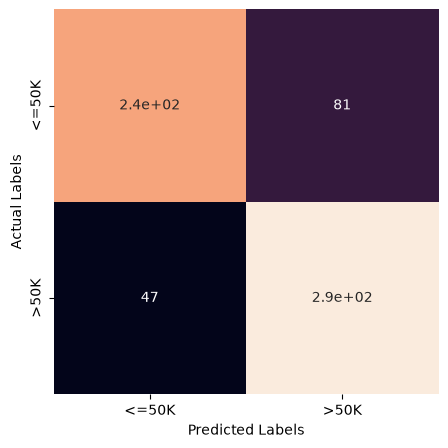

In [41]:
from sklearn.pipeline import Pipeline

# Reserve 30% of observations for held-out evaluation.
XX_ad_train, XX_ad_test, yy_ad_train, yy_ad_test = train_test_split(X_ad, y_ad,
                                                                    test_size=0.3,
                                                                    stratify=y_ad,
                                                                    random_state=43)

best_decision_tree_classifier_m_ad_prepost = Pipeline([
    # Encode unseen category values as -1 at prediction time.
    ('encoder', OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1)),
    ('sklearn_dt', grid_search.best_estimator_)
])
best_decision_tree_classifier_m_ad_prepost.fit(XX_ad_train, yy_ad_train)

ads.custom_crossvalidation(XX_ad_train, yy_ad_train, best_decision_tree_classifier_m_ad_prepost)

              precision    recall  f1-score   support

       <=50K       0.86      0.71      0.78       141
        >50K       0.76      0.89      0.82       144

    accuracy                           0.80       285
   macro avg       0.81      0.80      0.80       285
weighted avg       0.81      0.80      0.80       285



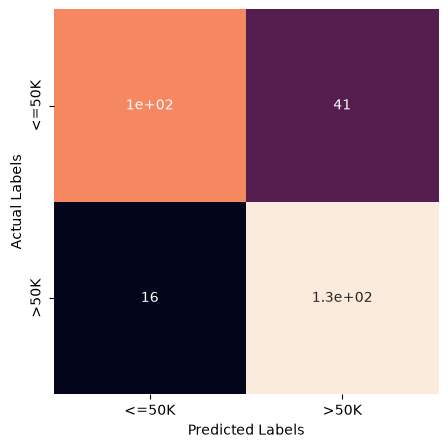

In [42]:
yy_ad_test_pred = best_decision_tree_classifier_m_ad_prepost.predict(XX_ad_test)
print(classification_report(yy_ad_test, yy_ad_test_pred))
ads.plot_confusion_matrix(yy_ad_test, yy_ad_test_pred)

## Gradient-boosted trees with XGBoost

The final estimator family uses XGBoost's categorical support and then applies a randomized hyperparameter search. The one-tree configuration is inspected before selecting a stronger model and comparing its performance with the earlier approaches.

In [43]:
from xgboost import XGBClassifier
import xgboost as xgb


XX_ad = X_ad.copy()
XX_ad_c = XX_ad.select_dtypes(include='object').columns
XX_ad[XX_ad_c] = XX_ad[XX_ad_c].astype('category')
XX_ad.info()

<class 'pandas.DataFrame'>
RangeIndex: 947 entries, 0 to 946
Data columns (total 14 columns):
 #   Column          Non-Null Count  Dtype   
---  ------          --------------  -----   
 0   age             947 non-null    float64 
 1   capital_gain    947 non-null    float64 
 2   capital_loss    947 non-null    float64 
 3   education       947 non-null    category
 4   education_num   947 non-null    float64 
 5   fnlwgt          947 non-null    float64 
 6   hours_per_week  947 non-null    float64 
 7   marital_status  947 non-null    category
 8   native_country  947 non-null    category
 9   occupation      947 non-null    category
 10  race            947 non-null    category
 11  relationship    947 non-null    category
 12  sex             947 non-null    category
 13  workclass       947 non-null    category
dtypes: category(8), float64(6)
memory usage: 52.6 KB


In [44]:
yy_ad = y_ad.copy()
yy_ad_e = yy_ad['label'].map({'<=50K': 0, '>50K': 1})
yy_ad_e.info()

<class 'pandas.Series'>
RangeIndex: 947 entries, 0 to 946
Series name: label
Non-Null Count  Dtype
--------------  -----
947 non-null    int64
dtypes: int64(1)
memory usage: 7.5 KB


In [45]:
yy_ad_e.value_counts()

label
1    480
0    467
Name: count, dtype: int64

In [46]:
# Form the training and evaluation partitions.
XX_ad_train, XX_ad_test, yy_ad_e_train, yy_ad_e_test = train_test_split(XX_ad, yy_ad_e, test_size=0.3, random_state=43)

Mean accuracy: 80.51% +/-2.77%
Mean precision: 81.20% +/-2.43%
Mean recall: 80.24% +/-2.96%
Mean F1-score is 80.25% +/-2.93%
              precision    recall  f1-score   support

           0       0.84      0.74      0.78       317
           1       0.78      0.87      0.82       345

    accuracy                           0.81       662
   macro avg       0.81      0.80      0.80       662
weighted avg       0.81      0.81      0.80       662



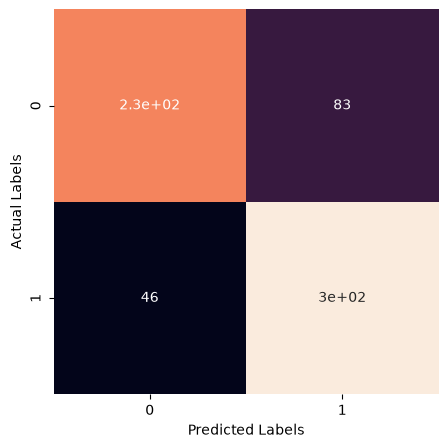

In [47]:
# Start with a single XGBoost tree before broader tuning.
xgb_dt_m_ad = XGBClassifier(enable_categorical=True, 
                            n_estimators=1, 
                            num_parallel_tree=1, 
                            objective='multi:softmax', 
                            booster='dart',
                            num_class=2, 
                            eval_metric='mlogloss',
                            random_state=43)
# Run the unchanged cross-validation summary.
ads.custom_crossvalidation(XX_ad_train, yy_ad_e_train, xgb_dt_m_ad)

In [48]:
xgb_dt_m_ad.fit(XX_ad_train, yy_ad_e_train)
xgb_dt_m_ad_tree_text = xgb_dt_m_ad.get_booster().get_dump(with_stats=True)
# Display the first learned tree in text form.
print(xgb_dt_m_ad_tree_text[0])

0:[marital_status:{2}] yes=2,no=1,missing=1,gain=114.576942,cover=330.407837
	1:[capital_gain<7298] yes=3,no=4,missing=4,gain=10.8739853,cover=131.763855
		3:[education:{2,10,12,13}] yes=8,no=7,missing=7,gain=5.99105072,cover=127.771004
			7:[age<34] yes=13,no=14,missing=14,gain=1.95393372,cover=112.797836
				13:[capital_loss<1762] yes=25,no=26,missing=26,gain=0.454502106,cover=66.8801346
					25:[workclass:{0}] yes=40,no=39,missing=39,gain=0.479400635,cover=65.3828201
						39:leaf=0.299174428,cover=63.8855019
						40:leaf=0.0676859319,cover=1.49731648
					26:leaf=0.0676859319,cover=1.49731648
				14:[occupation:{9,10}] yes=28,no=27,missing=27,gain=2.18442726,cover=45.9177055
					27:[fnlwgt<162834] yes=41,no=42,missing=42,gain=0.778936386,cover=39.4293327
						41:leaf=0.291609764,cover=13.4758482
						42:leaf=0.179194212,cover=25.9534855
					28:[education:{8,11}] yes=44,no=43,missing=43,gain=1.56249666,cover=6.48837137
						43:leaf=0.11073909,cover=4.99105501
						44:leaf=-0.

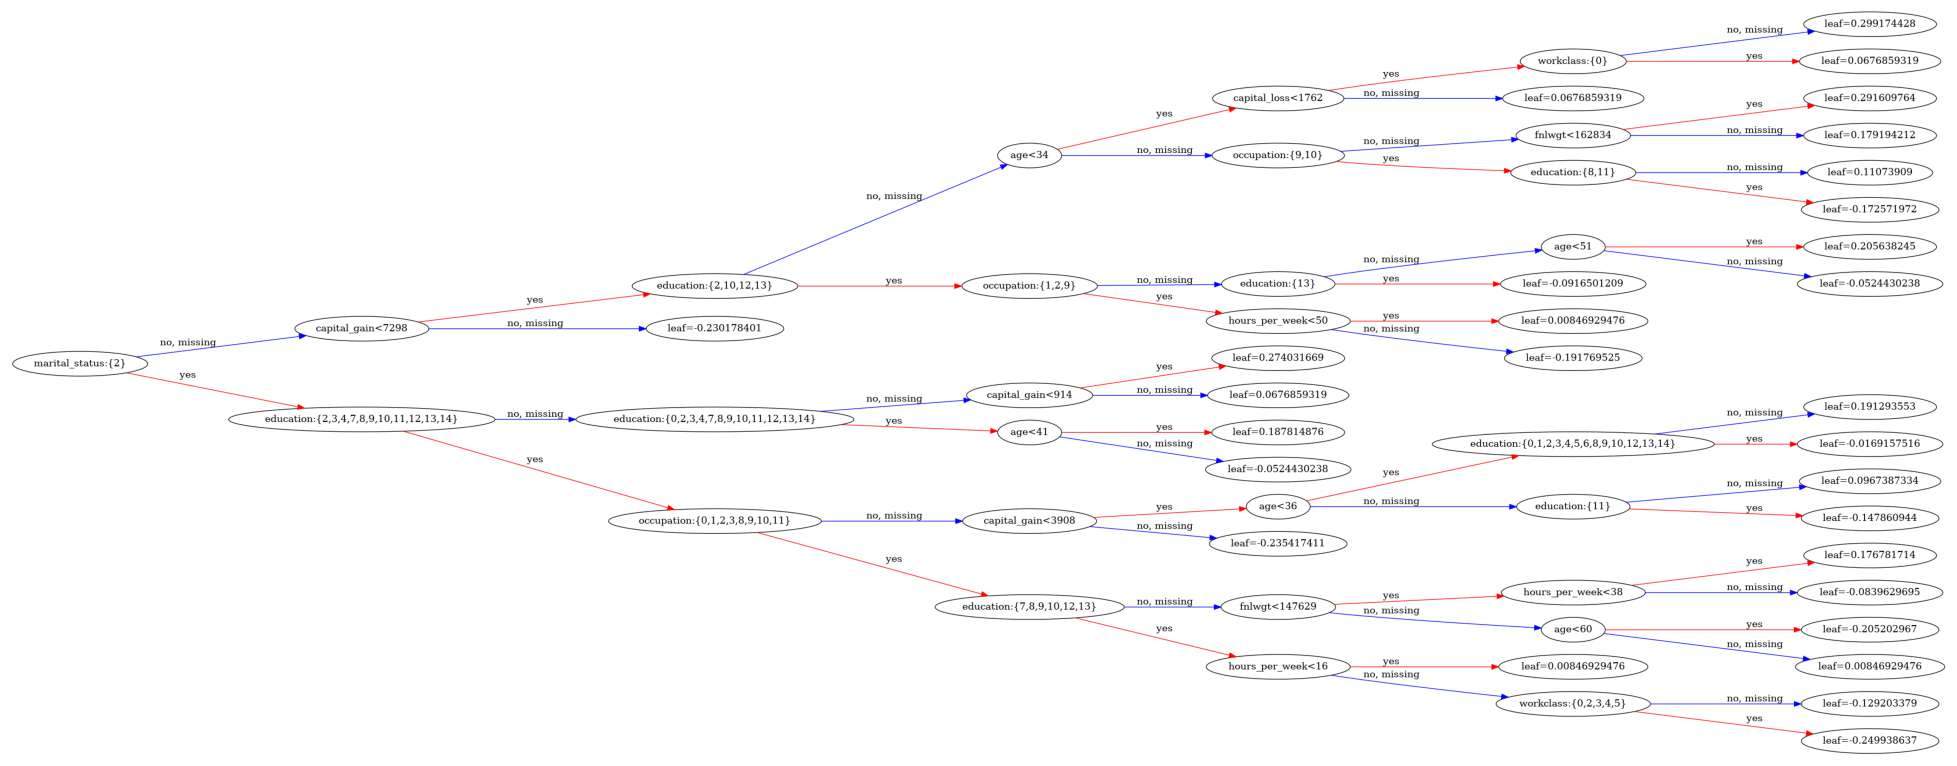

In [50]:

import graphviz
fig = plt.figure(figsize=(25, 16))
ax = fig.gca()
# Select which tree index to render.
xgb.plot_tree(xgb_dt_m_ad, num_trees=0, rankdir='LR', ax=ax)
plt.show()

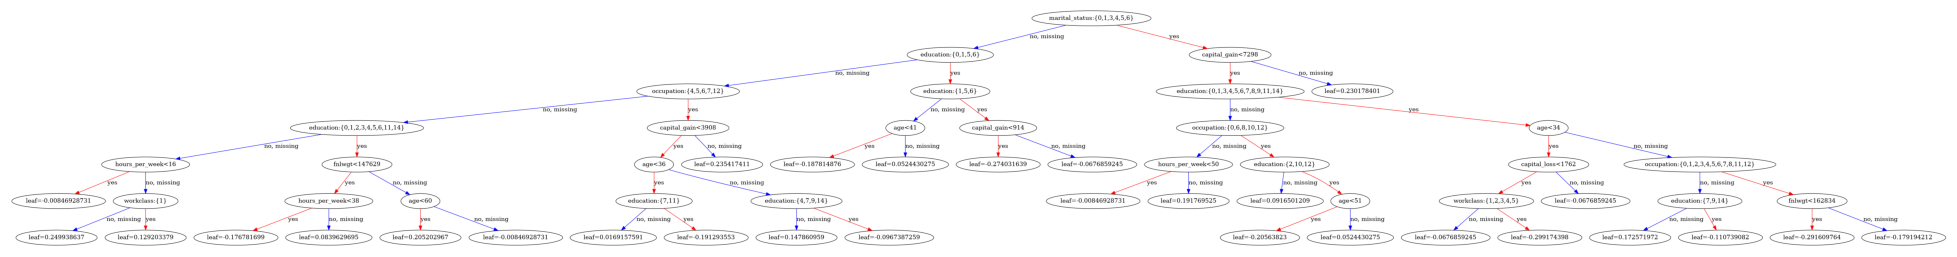

In [51]:
fig = plt.figure(figsize=(25, 40))
ax = fig.gca()
# Select which tree index to render.
xgb.plot_tree(xgb_dt_m_ad, num_trees=1, ax=ax)
plt.show()

In [52]:
# Define the randomized hyperparameter search.
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import uniform

params = {
    'max_depth' : range(3, 11),
    #'n_estimators': [1, 3, 5, 7],
    #'num_parallel_tree': [1, 3, 5],  # Number of trees to build in parallel per boosting round
    'max_leaves':[3, 5, 7, 10],
    'learning_rate': np.arange(0.1, 0.5, 0.1),
    'min_child_weight': range(1,6,2)
}

params2 = {
    #'n_estimators': [100, 200, 300, 400],
    'n_estimators': [21],
    'num_parallel_tree': [1],
    'learning_rate': uniform(0.01, 0.5),
    'max_depth' : range(3, 13),
    'subsample': uniform(0.6, 0.4),
    'colsample_bytree': uniform(0.6, 0.4),
    'gamma': uniform(0, 0.5),
    #'max_leaves':[3, 5, 7, 10],
    'min_child_weight': range(1,6,1)
}

random_search = RandomizedSearchCV(xgb_dt_m_ad, 
                                   param_distributions=params2, 
                                   n_iter=200, 
                                   cv=5, 
                                   n_jobs=-1, 
                                   random_state=43, 
                                   scoring='f1_macro')

# Search the candidate distributions on training data.
random_search.fit(XX_ad_train, yy_ad_e_train)
print(random_search.best_params_)


# Retain macro-F1 as the selection criterion.
# grid_search = GridSearchCV(xgb_dt_m_ad, param_grid=params3, scoring='f1_macro', cv=5)
# grid_search.fit(XX_ad_train, yy_ad_e_train)
# print(grid_search.best_params_)

{'colsample_bytree': np.float64(0.8269577821271451), 'gamma': np.float64(0.4425156886471609), 'learning_rate': np.float64(0.40750850117372656), 'max_depth': 3, 'min_child_weight': 2, 'n_estimators': 21, 'num_parallel_tree': 1, 'subsample': np.float64(0.8263684222276745)}


In [53]:
#(np.mean(grid_search.cv_results_['mean_test_score']),
#np.std(grid_search.cv_results_['mean_test_score']))
(np.mean(random_search.cv_results_['mean_test_score']),
np.std(random_search.cv_results_['mean_test_score']))

(np.float64(0.8087265957127725), np.float64(0.00836011302912573))

Mean accuracy: 83.39% +/-3.05%
Mean precision: 83.57% +/-2.95%
Mean recall: 83.26% +/-3.06%
Mean F1-score is 83.30% +/-3.08%
              precision    recall  f1-score   support

           0       0.84      0.80      0.82       317
           1       0.83      0.86      0.84       345

    accuracy                           0.83       662
   macro avg       0.83      0.83      0.83       662
weighted avg       0.83      0.83      0.83       662



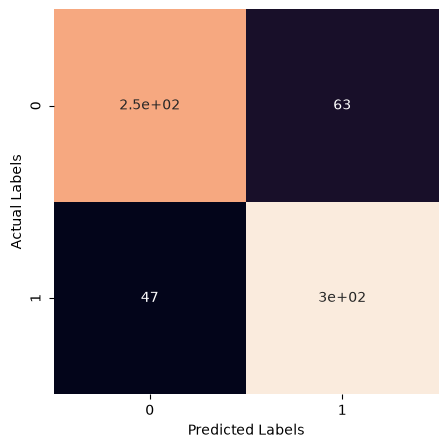

In [54]:
optimal_xgb = random_search.best_estimator_
ads.custom_crossvalidation(XX_ad_train, yy_ad_e_train, optimal_xgb)

              precision    recall  f1-score   support

           0       0.86      0.79      0.82       150
           1       0.78      0.86      0.82       135

    accuracy                           0.82       285
   macro avg       0.82      0.82      0.82       285
weighted avg       0.82      0.82      0.82       285



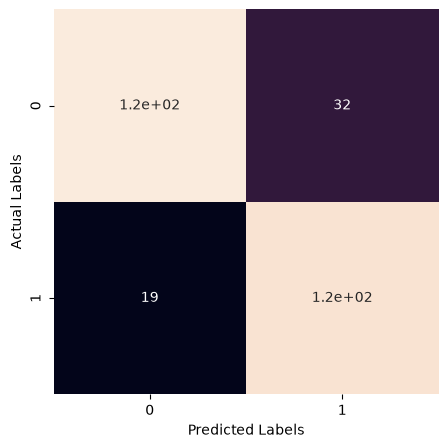

In [55]:
yy_ad_e_test_pred = optimal_xgb.predict(XX_ad_test)
print(classification_report(yy_ad_e_test, yy_ad_e_test_pred))
ads.plot_confusion_matrix(yy_ad_e_test, yy_ad_e_test_pred)

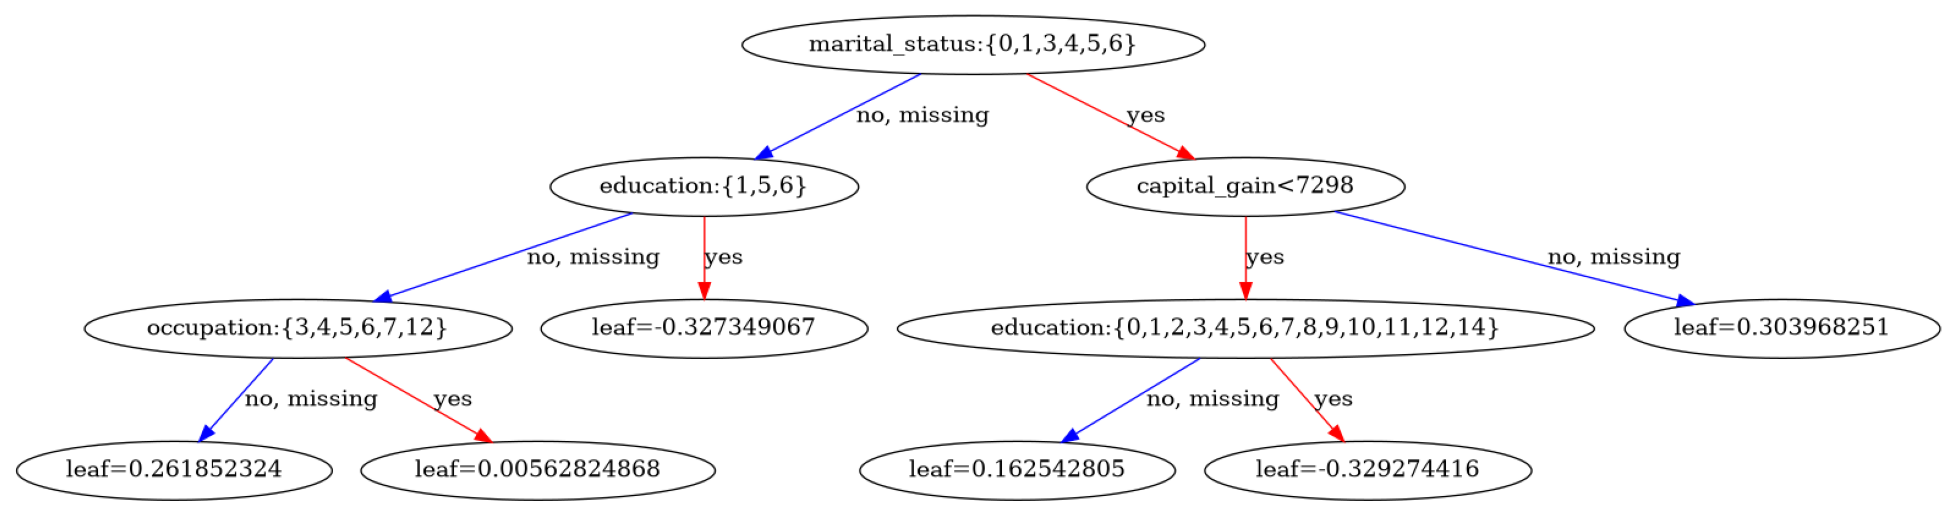

In [56]:
fig = plt.figure(figsize=(25, 16))
ax = fig.gca()
# Select which tree index to render.
xgb.plot_tree(optimal_xgb, num_trees=1, ax=ax)
plt.show()

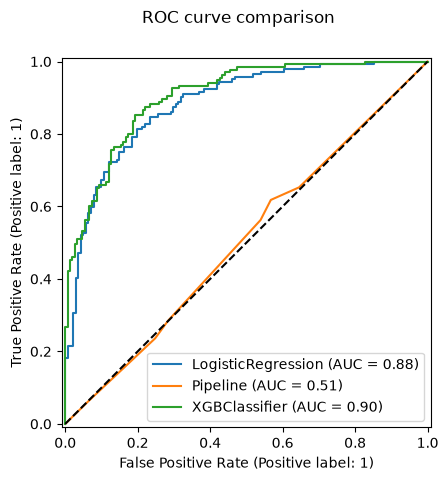

In [57]:
import matplotlib.pyplot as plt
from sklearn.metrics import RocCurveDisplay, roc_curve, auc

# Compare ROC traces for the three selected estimators.
best_lr_m_ad_disp = RocCurveDisplay.from_estimator(best_logistic_regression_m_ad, X_ad_e_s_test, y_ad_e_s_test)

best_dtc_m_ad_prepost_named_disp = RocCurveDisplay.from_estimator(
    best_decision_tree_classifier_m_ad_prepost,
    XX_ad_test, yy_ad_test,
    ax=best_lr_m_ad_disp.ax_
)

best_xgb_m_dt_disp = RocCurveDisplay.from_estimator(
    optimal_xgb,
    XX_ad_test, yy_ad_e_test,
    ax=best_dtc_m_ad_prepost_named_disp.ax_
)

best_xgb_m_dt_disp.figure_.suptitle("ROC curve comparison")
plt.plot([0, 1], [0, 1], 'k--')
